# 🚗 Analisis Perjalanan Ride-Hailing Semarang (Jan–Jun 2026)
**Oleh:** Ihsan Amiruddin · **Tools:** Python, Pandas, Matplotlib, Seaborn

> Studi kasus portofolio dengan **dataset simulasi**.

## Skenario
Sebuah layanan transportasi online lokal ingin memahami kapan permintaan memuncak, bagaimana tarif terbentuk, dan area mana yang paling potensial. Pertanyaan yang dijawab:
1. Jam berapa armada harus paling siaga?
2. Dari area mana ke area mana perjalanan paling sering terjadi?
3. Apakah perjalanan pendek terlalu mahal per kilometer?
4. Adakah pola kemacetan (kecepatan) sepanjang hari?
5. Apakah pelanggan lama tetap setia dari bulan ke bulan?

## 1. Load Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
rp = lambda x: f"Rp {x:,.0f}".replace(",", ".")


In [2]:
# Di Google Colab: upload file CSV ke panel kiri, lalu sesuaikan PATH bila perlu
import os
PATH = "data/ride_hailing_trip_analysis_raw.csv" if os.path.exists("data/ride_hailing_trip_analysis_raw.csv") else "ride_hailing_trip_analysis_raw.csv"
df_raw = pd.read_csv(PATH)
df_raw.head()

,trip_id,date,time,pickup_area,dropoff_area,vehicle_type,distance_km,duration_minutes,fare,payment_method,customer_type
0,TRIP01937,2026-01-01,00:52,Banyumanik,Tembalang,Motor,2.1,23,13500,QRIS,Returning Customer
1,TRIP01678,2026-01-01,05:46,Pedurungan,Pedurungan,Mobil,11.5,40,69500,QRIS,Returning Customer
2,TRIP02971,2026-01-01,06:27,Simpang Lima,Bandara Ahmad Yani,Mobil,7.1,24,47500,E-Wallet,Returning Customer
3,TRIP02253,2026-01-01,06:56,Simpang Lima,Simpang Lima,Motor,2.0,7,13000,Debit,Returning Customer
4,TRIP00855,2026-01-01,07:37,Candisari,Undip,Motor,4.9,22,24500,QRIS,Returning Customer


## 2. Data Understanding

In [3]:
print("Ukuran:", df_raw.shape)
df_raw.info()
print("\nMissing value:"); print(df_raw.isna().sum()[lambda s: s > 0])
print("\nBaris dobel:", df_raw.duplicated().sum())

Ukuran: (4015, 11)
<class 'pandas.DataFrame'>
RangeIndex: 4015 entries, 0 to 4014
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   trip_id           4015 non-null   str    
 1   date              4015 non-null   str    
 2   time              4015 non-null   str    
 3   pickup_area       4015 non-null   str    
 4   dropoff_area      4009 non-null   str    
 5   vehicle_type      4015 non-null   str    
 6   distance_km       4015 non-null   float64
 7   duration_minutes  4015 non-null   int64  
 8   fare              4015 non-null   int64  
 9   payment_method    4007 non-null   str    
 10  customer_type     4009 non-null   str    
dtypes: float64(1), int64(2), str(8)
memory usage: 633.4 KB

Missing value:
dropoff_area      6
payment_method    8
customer_type     6
dtype: int64

Baris dobel: 15


**Temuan kualitas data:** 15 perjalanan dobel (dihapus) dan data kosong di `dropoff_area`, `payment_method`, `customer_type` (diisi `Unknown`).

## 3. Data Cleaning

In [4]:
df = df_raw.drop_duplicates(subset="trip_id").copy()
for c in ["dropoff_area", "payment_method", "customer_type"]:
    df[c] = df[c].fillna("Unknown")
df["date"] = pd.to_datetime(df["date"])
df["hour"] = df["time"].str[:2].astype(int)
df["month"] = df["date"].dt.to_period("M").astype(str)
df["day_name"] = df["date"].dt.day_name()
df["fare_per_km"] = df.fare / df.distance_km
print("Data bersih:", df.shape)
os.makedirs("data", exist_ok=True); df.to_csv("data/ride_hailing_clean.csv", index=False)

Data bersih: (4000, 15)


## 4. KPI

In [5]:
print("Total pendapatan  :", rp(df.fare.sum()))
print("Jumlah perjalanan :", f"{len(df):,}")
print("Rata-rata tarif   :", rp(df.fare.mean()))
print("Rata-rata jarak   :", round(df.distance_km.mean(), 1), "km")
print("Korelasi jarak-tarif:", round(df.distance_km.corr(df.fare), 2))

Total pendapatan  : Rp 112.949.000
Jumlah perjalanan : 4,000
Rata-rata tarif   : Rp 28.237
Rata-rata jarak   : 5.0 km
Korelasi jarak-tarif: 0.83


## 5. Tren Bulanan

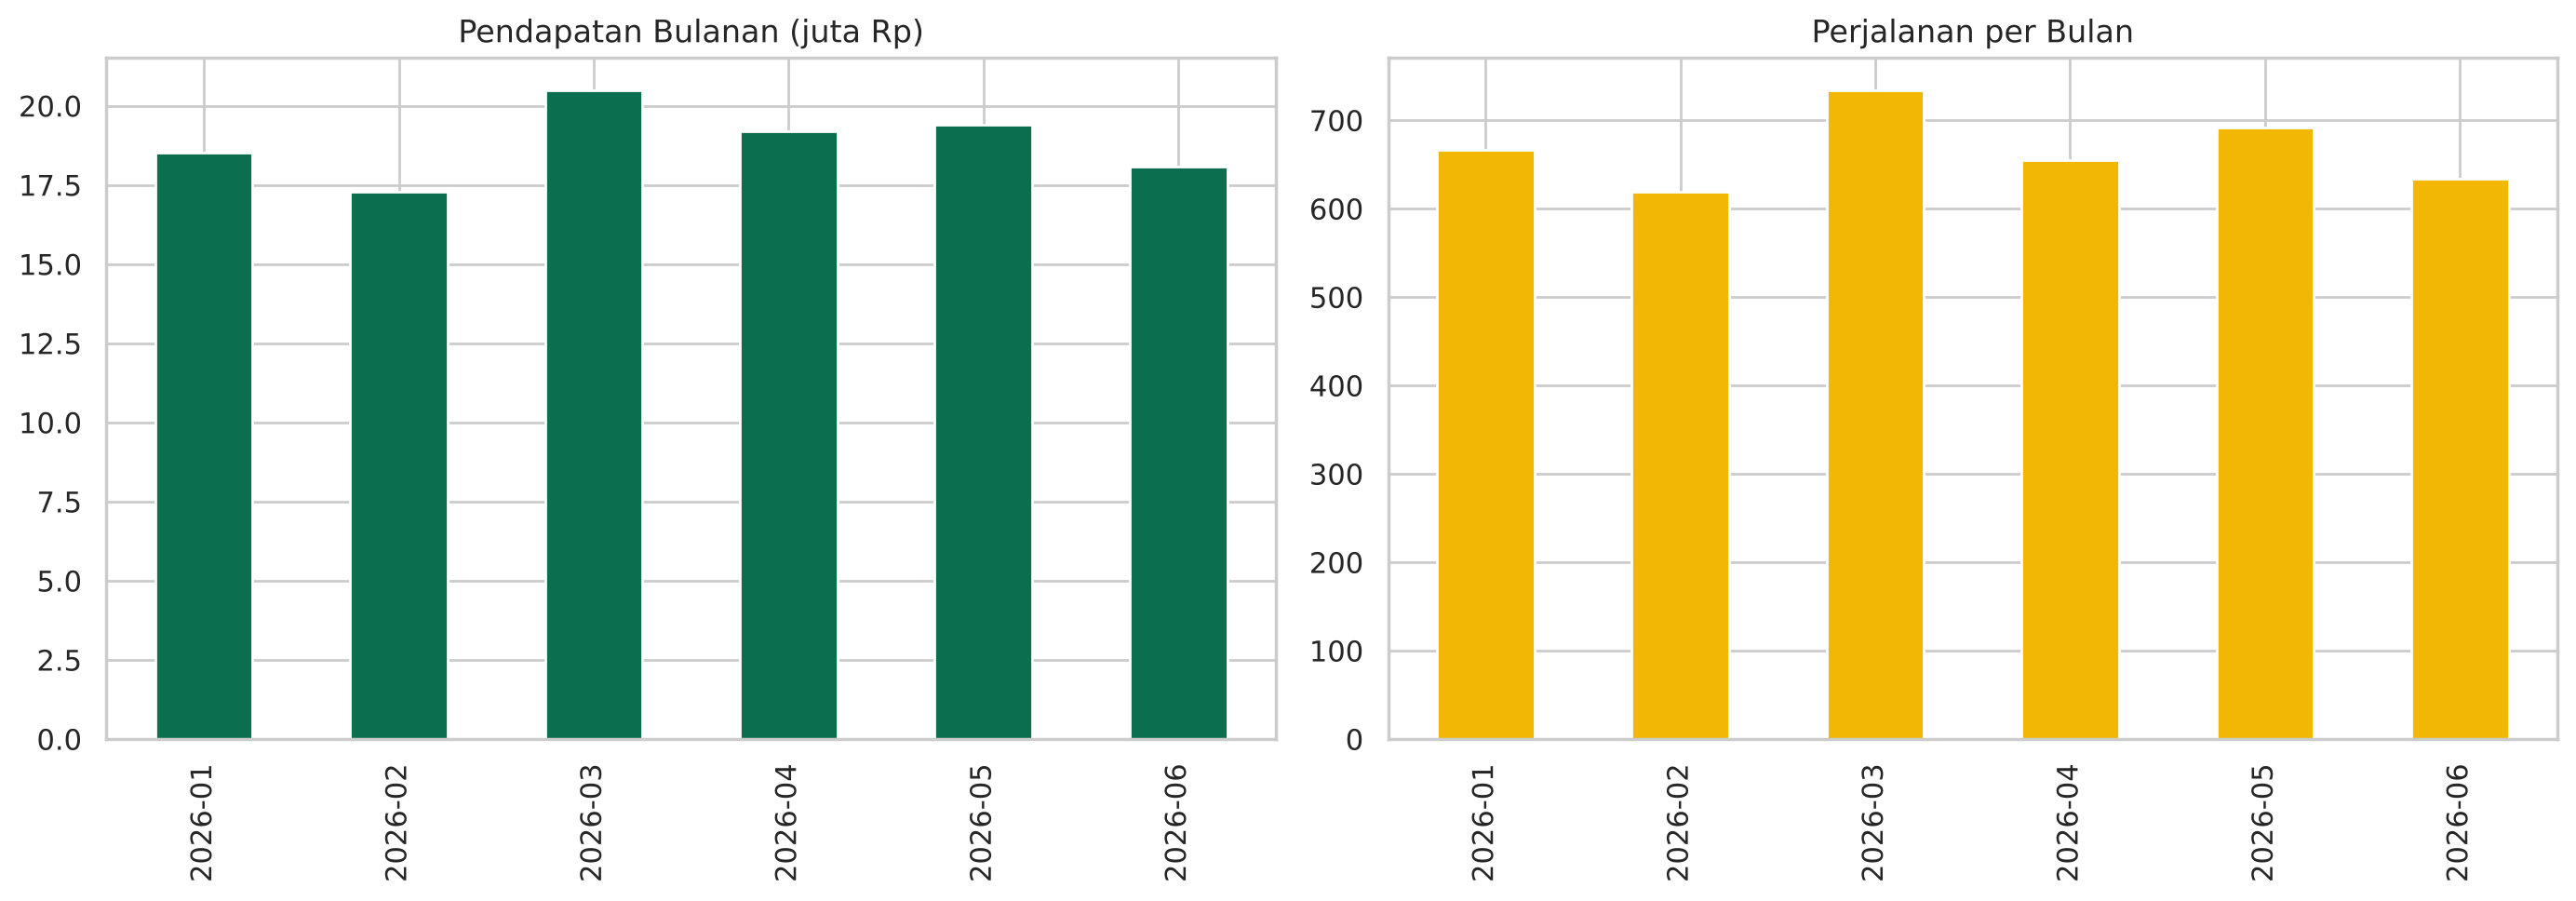

In [6]:
g = df.groupby("month").agg(pendapatan=("fare","sum"), perjalanan=("fare","size"))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
(g.pendapatan / 1e6).plot(kind="bar", ax=ax[0], color="#0B6E4F"); ax[0].set_title("Pendapatan Bulanan (juta Rp)"); ax[0].set_xlabel("")
g.perjalanan.plot(kind="bar", ax=ax[1], color="#F2B705"); ax[1].set_title("Perjalanan per Bulan"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

**Insight:** Maret tertinggi (±Rp20,5 juta; 734 perjalanan), Februari terendah (±Rp17,3 juta; 619 perjalanan). Pendapatan bergerak mengikuti jumlah perjalanan.

## 6. Jam Sibuk

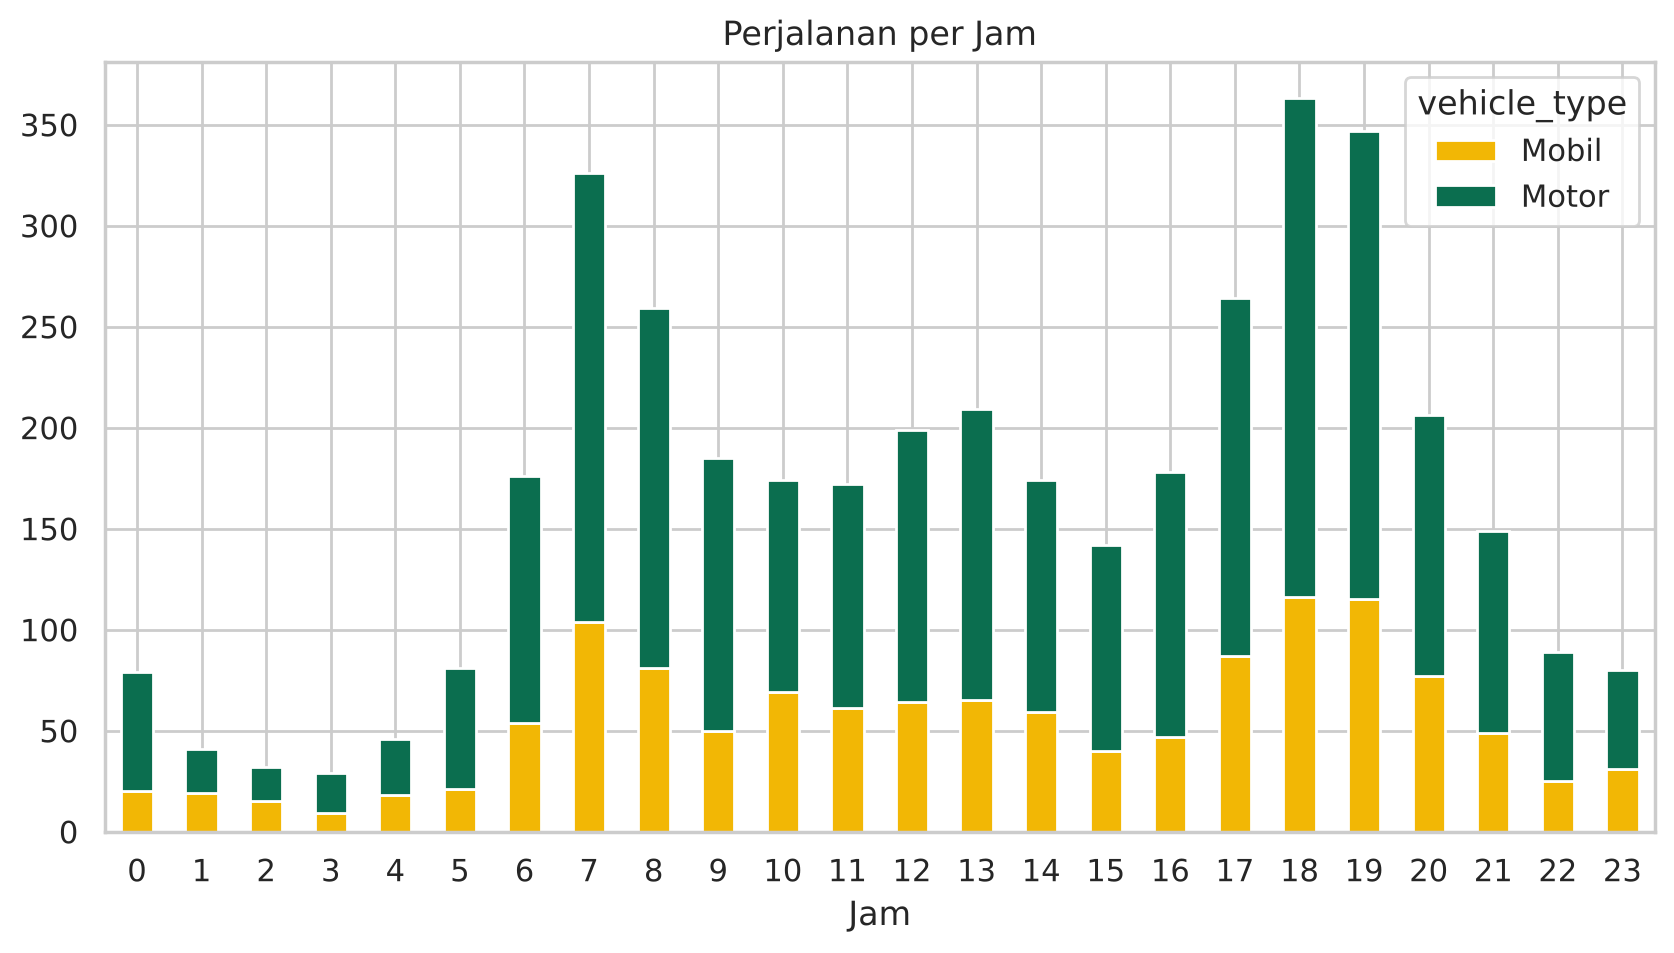

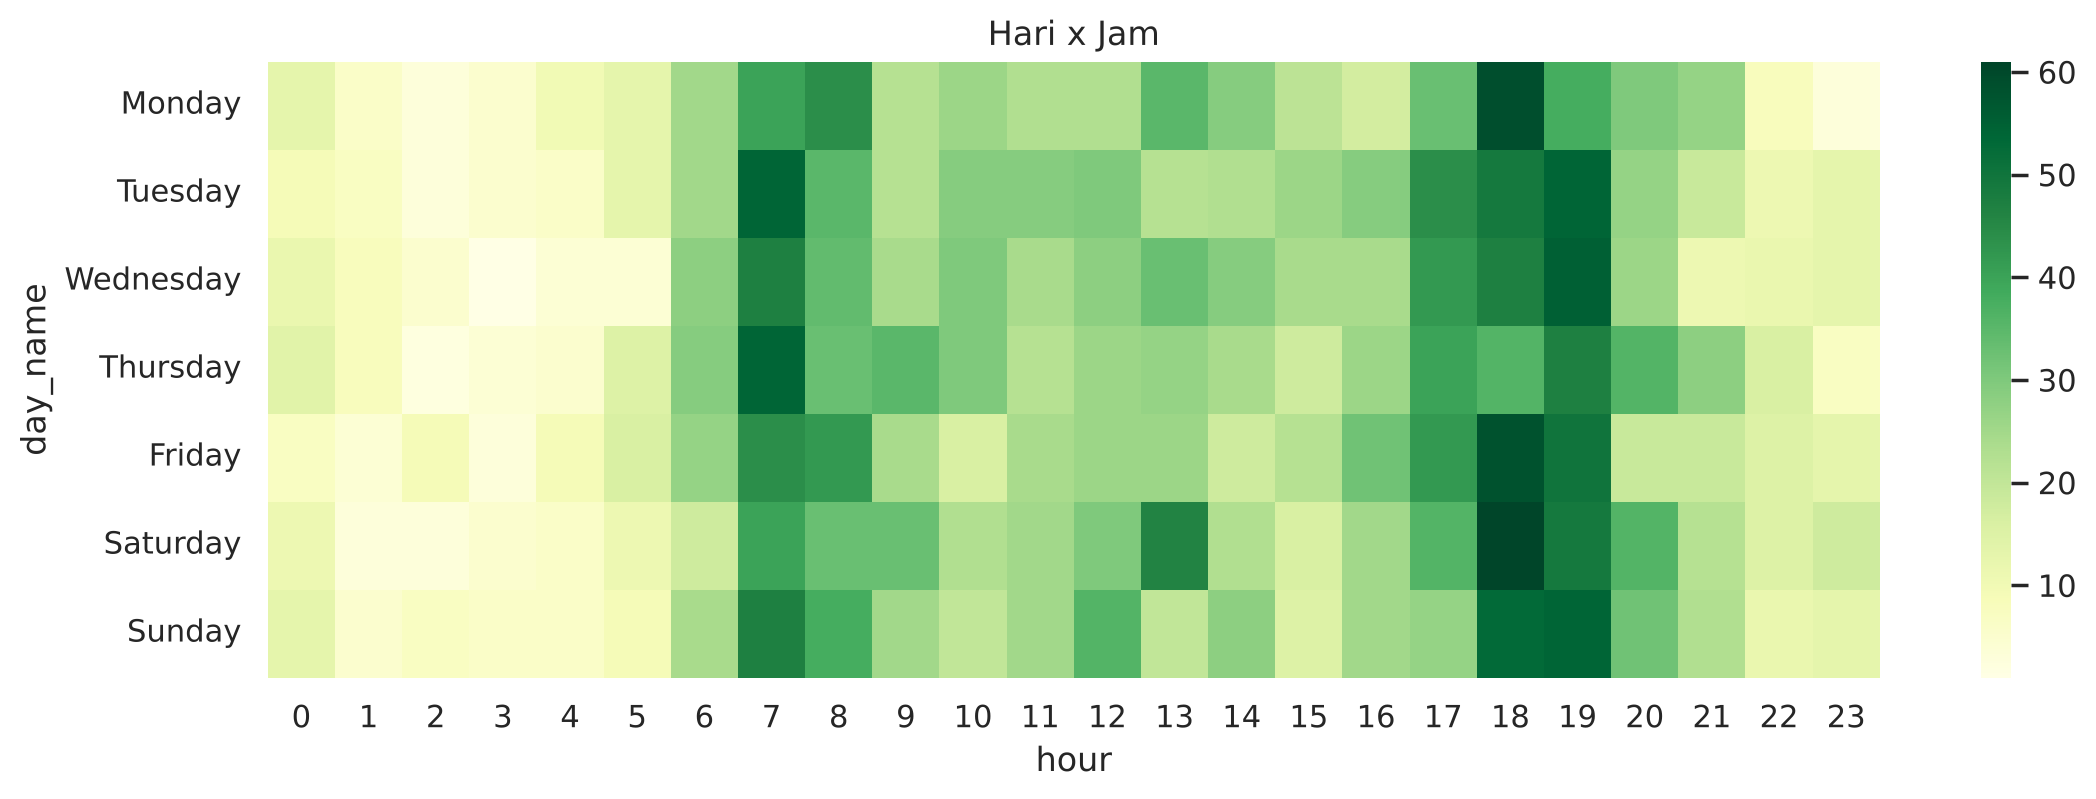

In [7]:
j = df.groupby(["hour","vehicle_type"]).size().unstack()
j.plot(kind="bar", stacked=True, color=["#F2B705", "#0B6E4F"]); plt.title("Perjalanan per Jam"); plt.xlabel("Jam"); plt.xticks(rotation=0); plt.show()
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
hm = df.pivot_table(index="day_name", columns="hour", values="trip_id", aggfunc="count", fill_value=0).reindex(order)
plt.figure(figsize=(13, 4)); sns.heatmap(hm, cmap="YlGn"); plt.title("Hari x Jam"); plt.show()

**Insight:** Ada **dua puncak berangkat/pulang kerja**: pagi (jam 07.00 = 326 perjalanan) dan sore (jam 18.00 = 363, jam 19.00 = 347). Dini hari jam 02.00–03.00 paling sepi (±30 perjalanan per jam). Tarif rata-rata juga tertinggi di jam puncak (±Rp31 ribu di jam 07.00 dan 18.00).

## 7. Motor vs Mobil

              perjalanan    tarif  jarak  tarif_per_km  persen
vehicle_type                                                  
Mobil               1296  38529.3    4.9        9145.0    32.4
Motor               2704  23304.4    5.1        5418.0    67.6


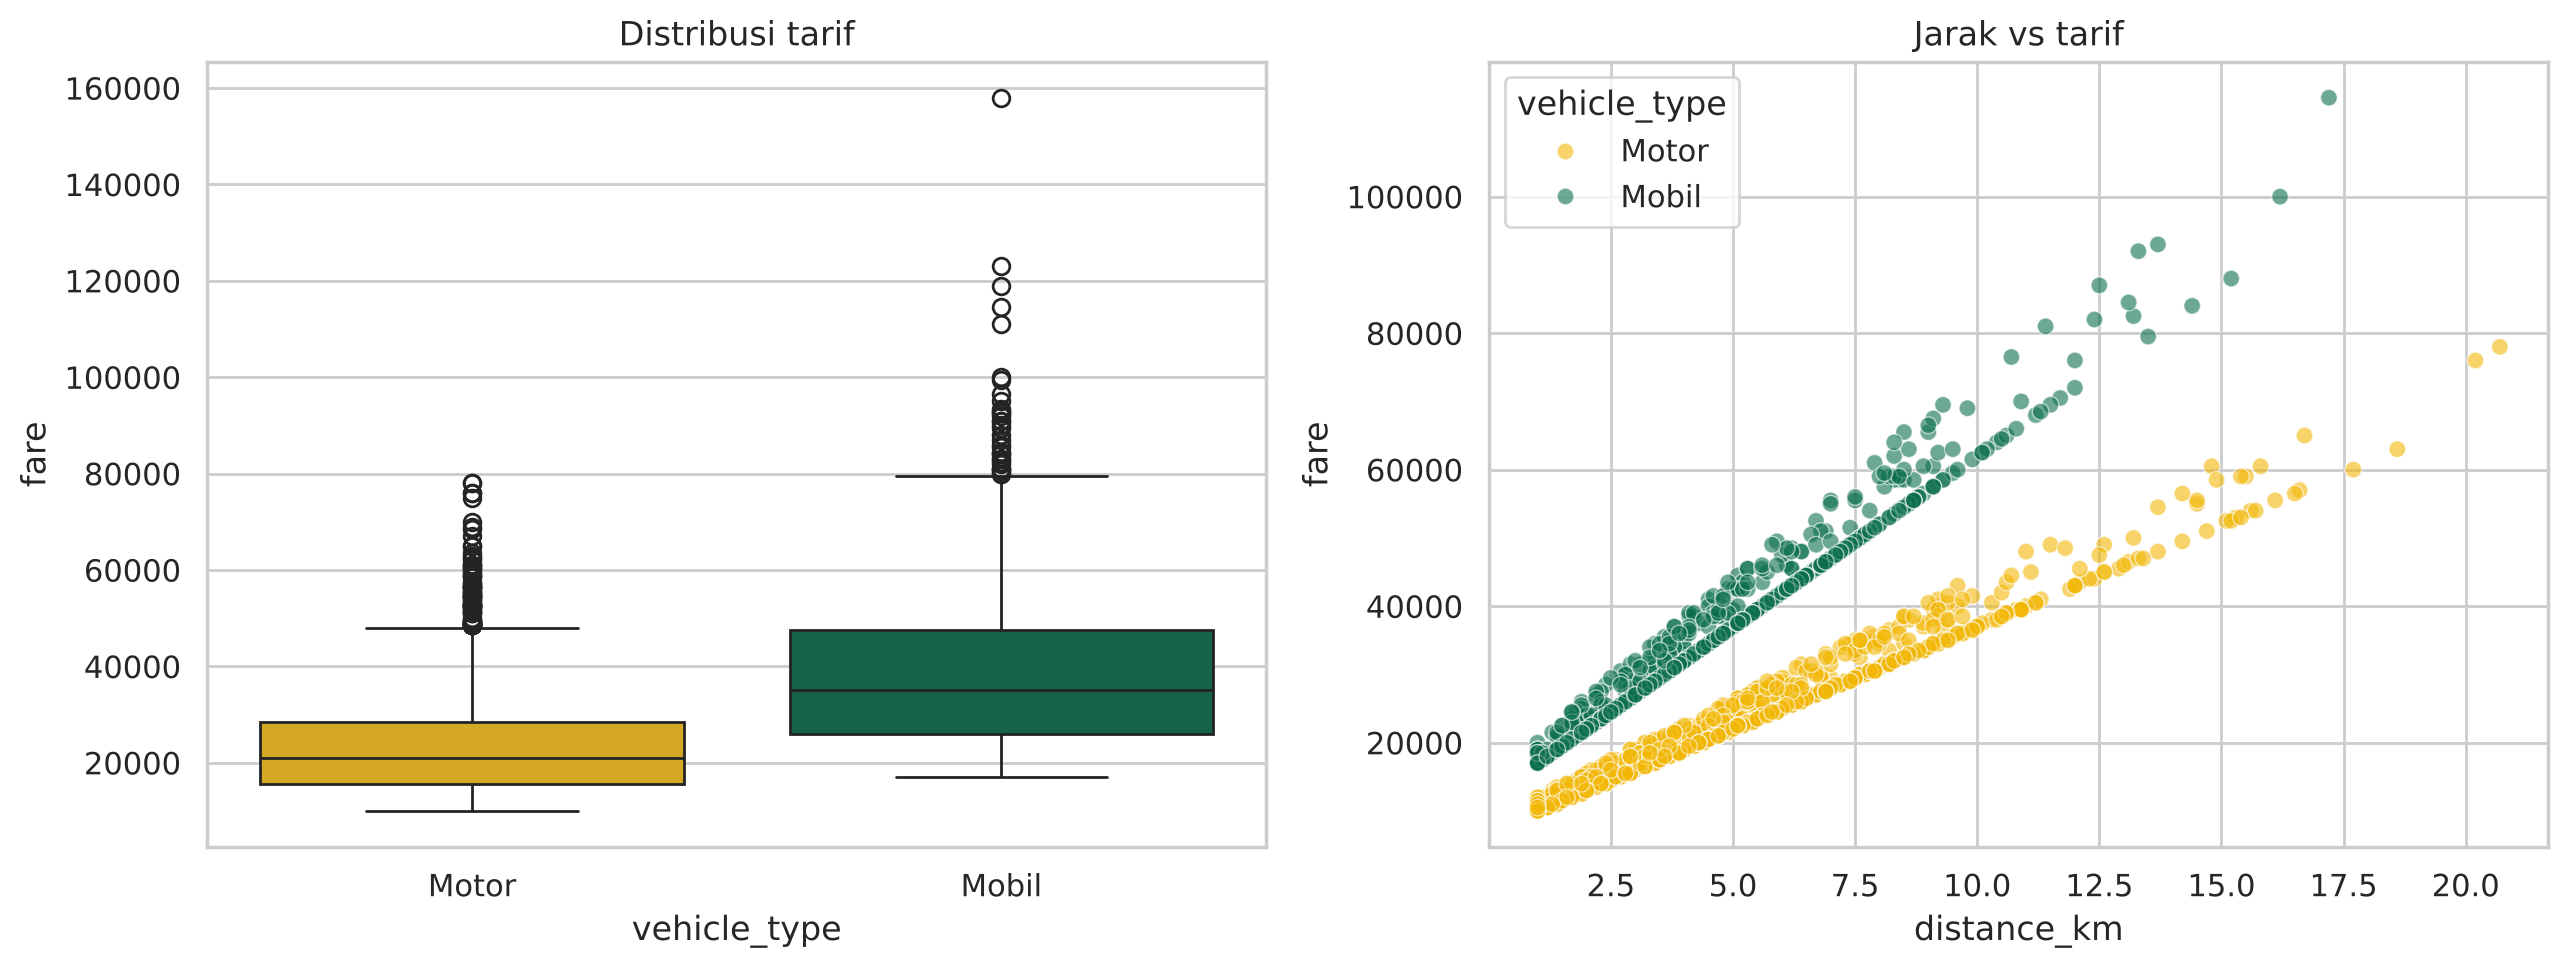

In [8]:
v = df.groupby("vehicle_type").agg(perjalanan=("fare","size"), tarif=("fare","mean"), jarak=("distance_km","mean"), tarif_per_km=("fare_per_km","mean")).round(1)
v["persen"] = (v.perjalanan / v.perjalanan.sum() * 100).round(1); print(v)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df, x="vehicle_type", y="fare", palette=["#F2B705", "#0B6E4F"], hue="vehicle_type", legend=False, ax=ax[0]); ax[0].set_title("Distribusi tarif")
sns.scatterplot(data=df.sample(1500, random_state=1), x="distance_km", y="fare", hue="vehicle_type", palette=["#F2B705", "#0B6E4F"], alpha=.6, ax=ax[1]); ax[1].set_title("Jarak vs tarif")
plt.tight_layout(); plt.show()

**Insight:** Motor 67,6% perjalanan, Mobil 32,4%. Jarak rata-rata hampir sama (±5 km), tetapi tarif Mobil (±Rp38,5 ribu) jauh di atas Motor (±Rp23,3 ribu), atau sekitar Rp9.100 vs Rp5.400 per km. Jarak berkorelasi kuat dengan tarif (±0,83).

## 8. Area & Rute

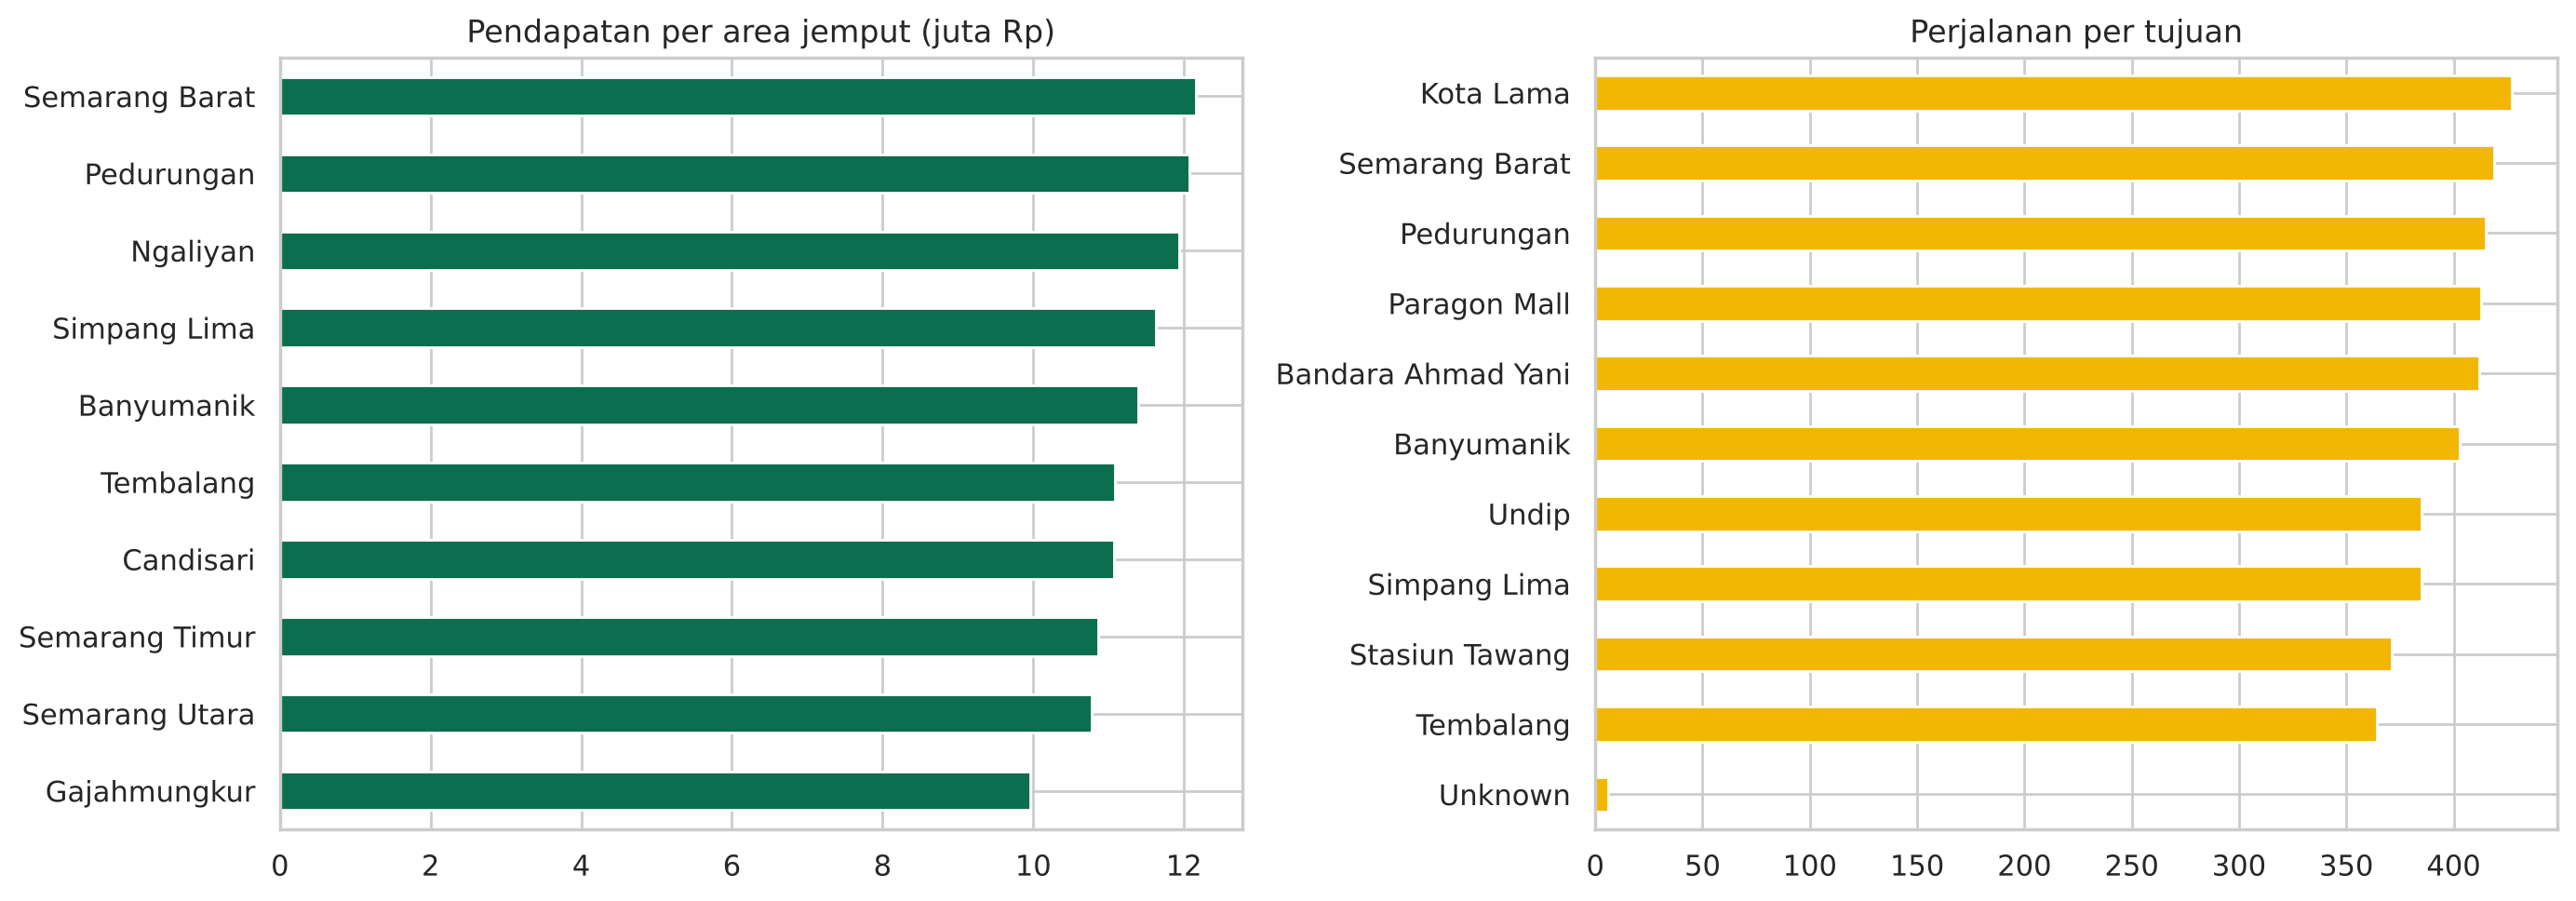

Simpang Lima → Simpang Lima        56
Candisari → Banyumanik             53
Semarang Timur → Semarang Barat    53
Tembalang → Undip                  53
Ngaliyan → Semarang Barat          50
Gajahmungkur → Pedurungan          49
Tembalang → Semarang Barat         49
Ngaliyan → Stasiun Tawang          49
Pedurungan → Pedurungan            48
Semarang Barat → Kota Lama         48
Name: count, dtype: int64
Jemput dan tujuan di area sama: 215 perjalanan


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
(df.groupby("pickup_area").fare.sum().sort_values() / 1e6).plot(kind="barh", ax=ax[0], color="#0B6E4F"); ax[0].set_title("Pendapatan per area jemput (juta Rp)"); ax[0].set_ylabel("")
df.groupby("dropoff_area").size().sort_values().plot(kind="barh", ax=ax[1], color="#F2B705"); ax[1].set_title("Perjalanan per tujuan"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()
rute = (df.pickup_area + " → " + df.dropoff_area).value_counts().head(10); print(rute)
print("Jemput dan tujuan di area sama:", (df.pickup_area == df.dropoff_area).sum(), "perjalanan")

**Insight:** Permintaan antar area **merata** (tiap area jemput ±380–420 perjalanan), tanpa satu area dominan; Semarang Barat sedikit unggul dalam pendapatan (±Rp12,2 juta). Ada 215 perjalanan (±5,4%) dengan titik jemput dan tujuan di area yang sama (perjalanan jarak dekat).

## 9. Pembayaran & Pelanggan

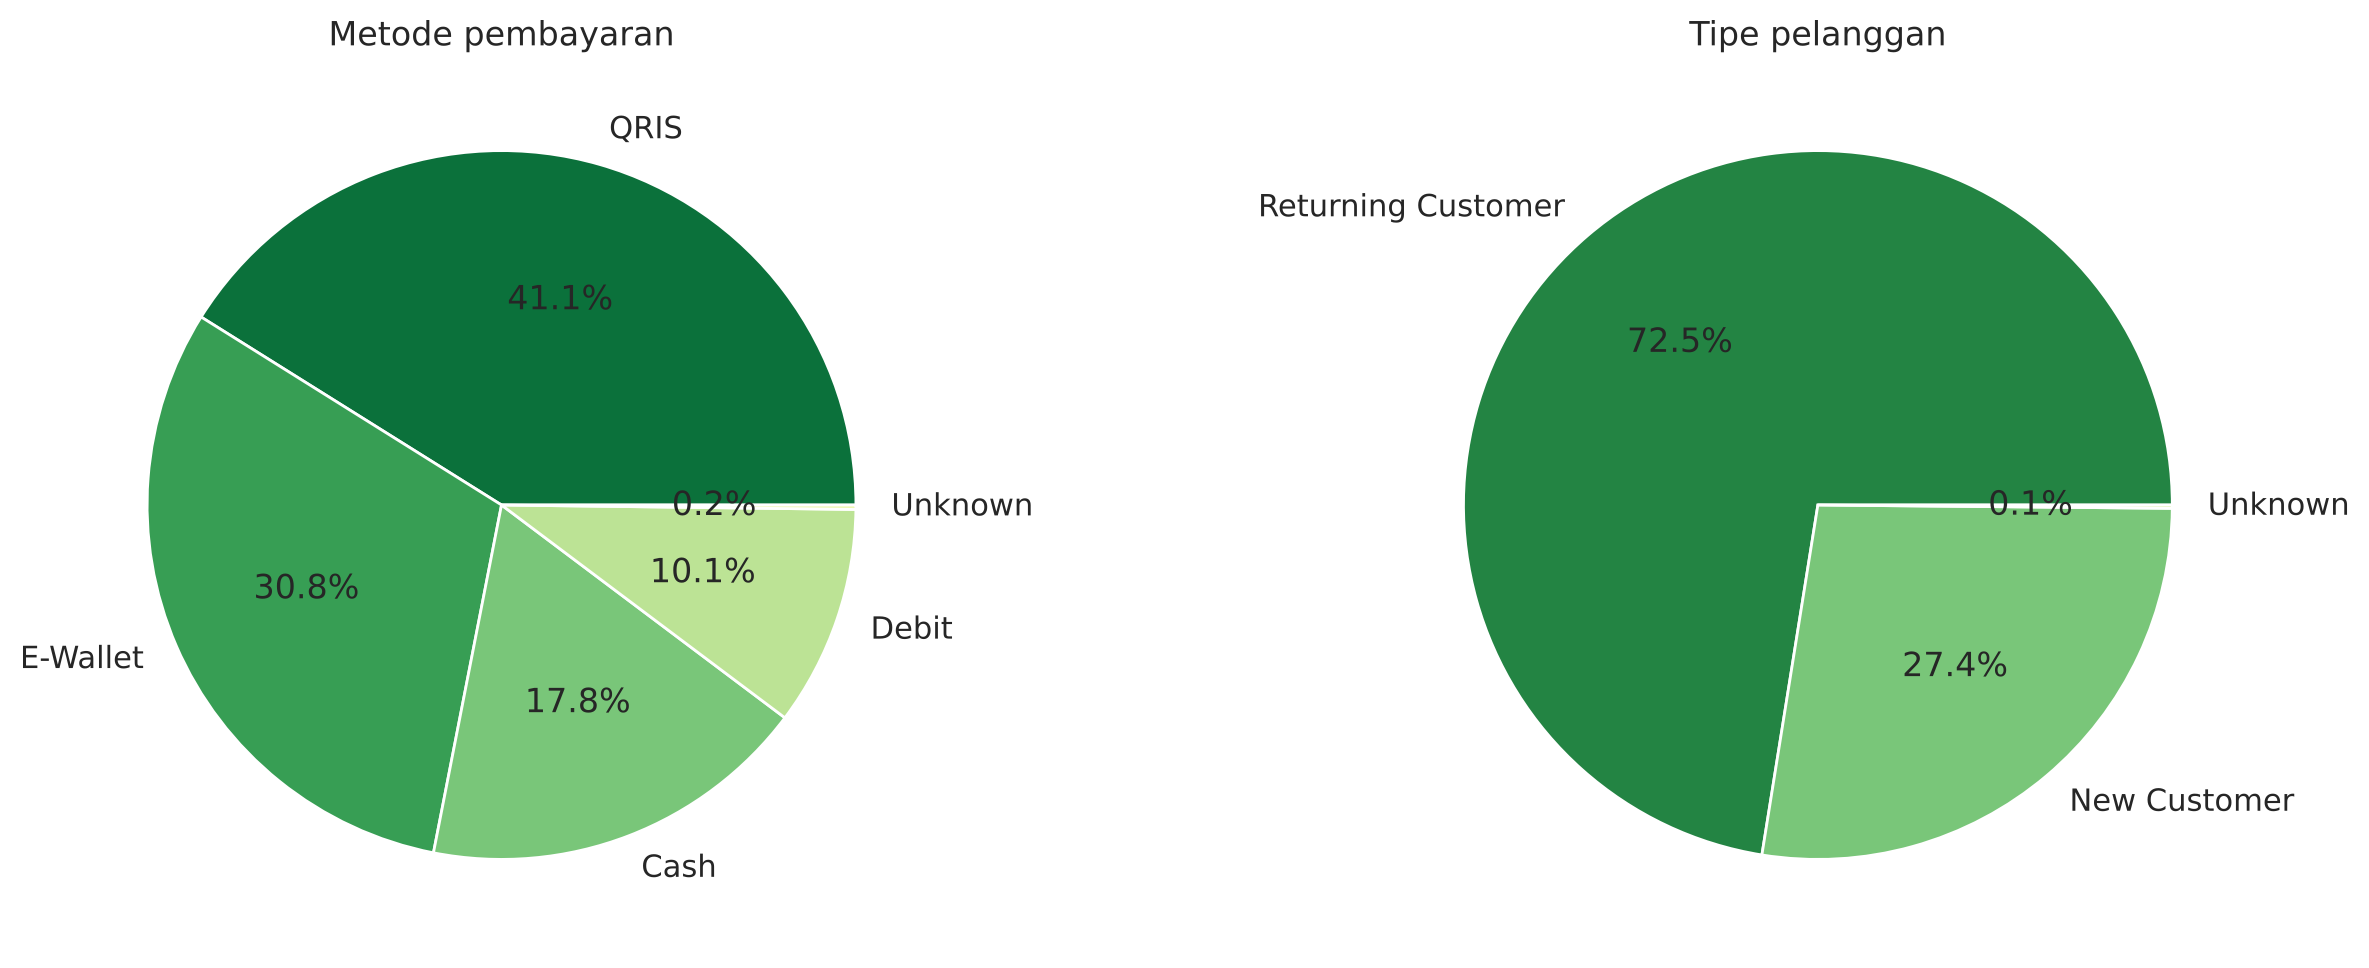

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
df.payment_method.value_counts().plot(kind="pie", autopct="%1.1f%%", ax=ax[0], colors=sns.color_palette("YlGn_r", 5)); ax[0].set_ylabel(""); ax[0].set_title("Metode pembayaran")
df.customer_type.value_counts().plot(kind="pie", autopct="%1.1f%%", ax=ax[1], colors=sns.color_palette("YlGn_r", 3)); ax[1].set_ylabel(""); ax[1].set_title("Tipe pelanggan")
plt.tight_layout(); plt.show()

**Insight:** QRIS ±41% dan E-Wallet ±31%; pembayaran non-tunai sekitar 82%. Pelanggan lama ±73% dari perjalanan, sehingga retensi pelanggan sudah baik; nilai tarif pelanggan baru dan lama hampir sama.

## Analisis Lanjutan (dipakai di dashboard)

         perjalanan    tarif  tarif_per_km
bucket                                    
<=2 km          694  14458.0       10528.0
2-5 km         1635  22571.0        6596.0
5-10 km        1384  35764.0        5142.0
>10 km          287  57538.0        4511.0

Kecepatan rata-rata per jam (km/jam):
{0: 13.7, 1: 13.6, 2: 14.1, 3: 13.8, 4: 16.0, 5: 13.5, 6: 13.2, 7: 14.5, 8: 14.1, 9: 13.8, 10: 13.8, 11: 13.8, 12: 13.0, 13: 13.9, 14: 14.0, 15: 13.4, 16: 14.5, 17: 13.8, 18: 14.1, 19: 13.9, 20: 13.2, 21: 13.6, 22: 14.1, 23: 13.7}

Kecepatan Motor vs Mobil: {'Mobil': 13.7, 'Motor': 13.9}


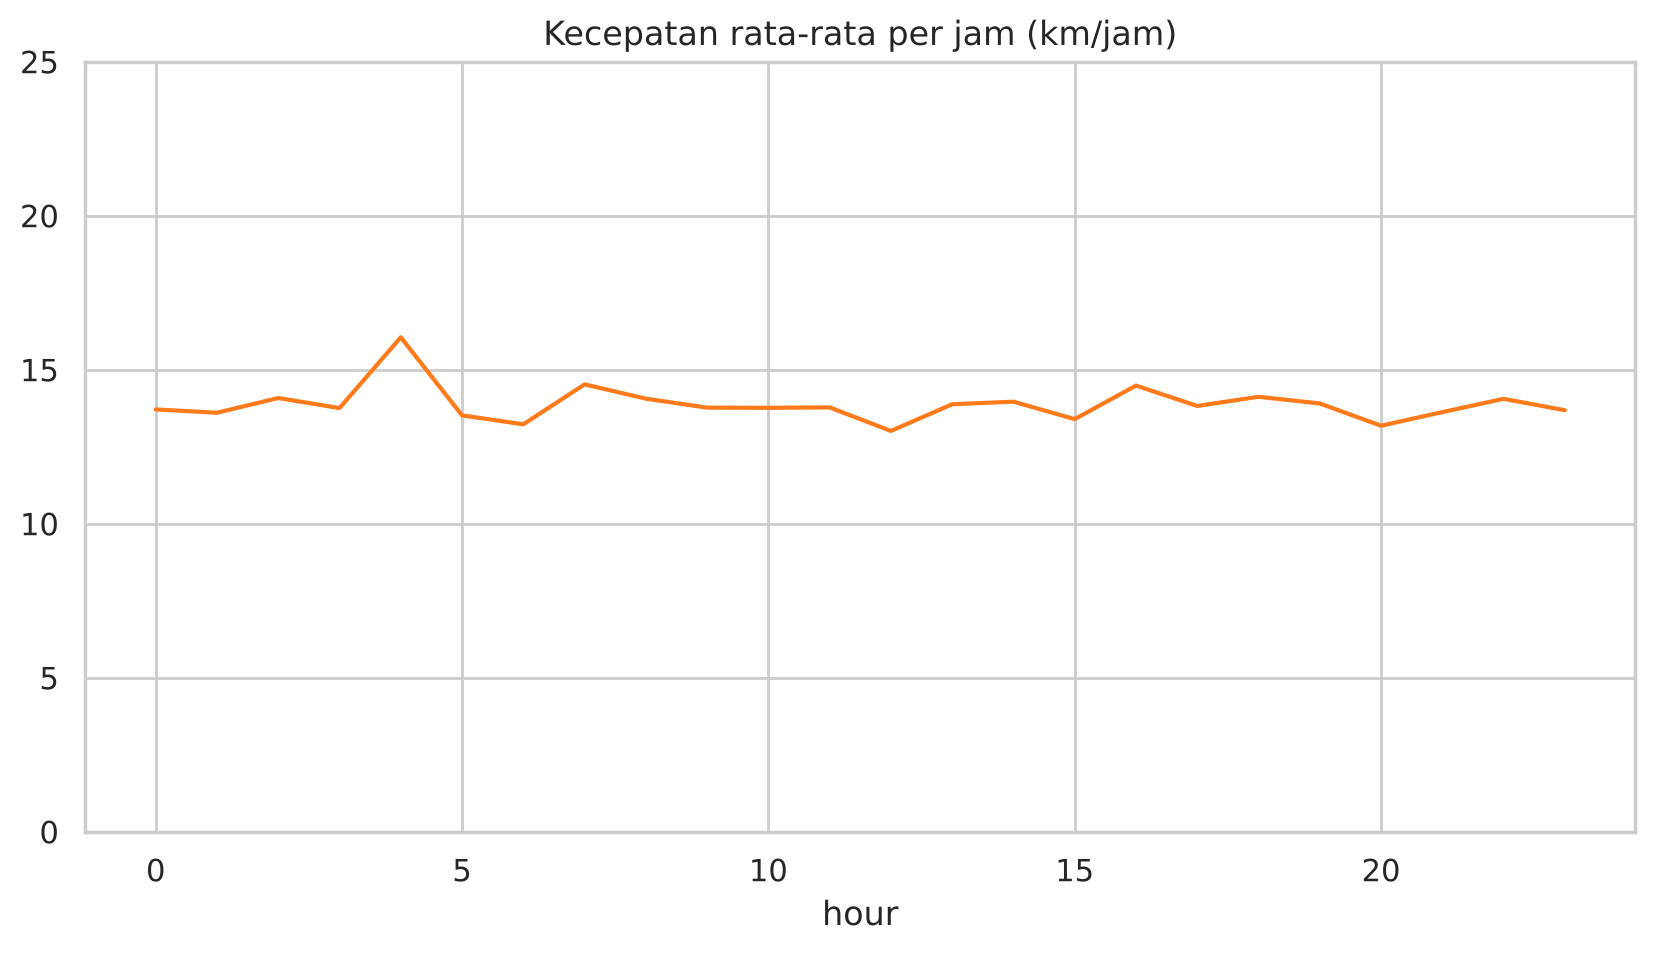

In [11]:
df["speed"] = df.distance_km / (df.duration_minutes / 60)
df["bucket"] = pd.cut(df.distance_km, [0, 2, 5, 10, 100], labels=["<=2 km", "2-5 km", "5-10 km", ">10 km"])
b = df.groupby("bucket", observed=True).agg(perjalanan=("fare","size"), tarif=("fare","mean"), tarif_per_km=("fare_per_km","mean")).round(0); print(b)
print("\nKecepatan rata-rata per jam (km/jam):"); print(df.groupby("hour").speed.mean().round(1).to_dict())
print("\nKecepatan Motor vs Mobil:", df.groupby("vehicle_type").speed.mean().round(1).to_dict())
df.groupby("hour").speed.mean().plot(color="#FF7A1A"); plt.ylim(0, 25); plt.title("Kecepatan rata-rata per jam (km/jam)"); plt.show()

**Insight:** Perjalanan <=2 km bertarif ±Rp10.500/km, lebih dari dua kali perjalanan >10 km (±Rp4.500/km), efek tarif dasar. Kecepatan rata-rata datar di ±13–14 km/jam sepanjang hari dan sama untuk Motor dan Mobil, jadi jam puncak tidak membuat perjalanan melambat di data ini.

Rute teratas:
pickup_area     dropoff_area  
Simpang Lima    Simpang Lima      56
Candisari       Banyumanik        53
Semarang Timur  Semarang Barat    53
Tembalang       Undip             53
Ngaliyan        Semarang Barat    50
dtype: int64

Tujuan Bandara+Stasiun: % 19.6

% pelanggan lama per bulan:
month
2026-01    74.0
2026-02    75.1
2026-03    73.7
2026-04    69.6
2026-05    72.7
2026-06    69.6
Name: customer_type, dtype: float64


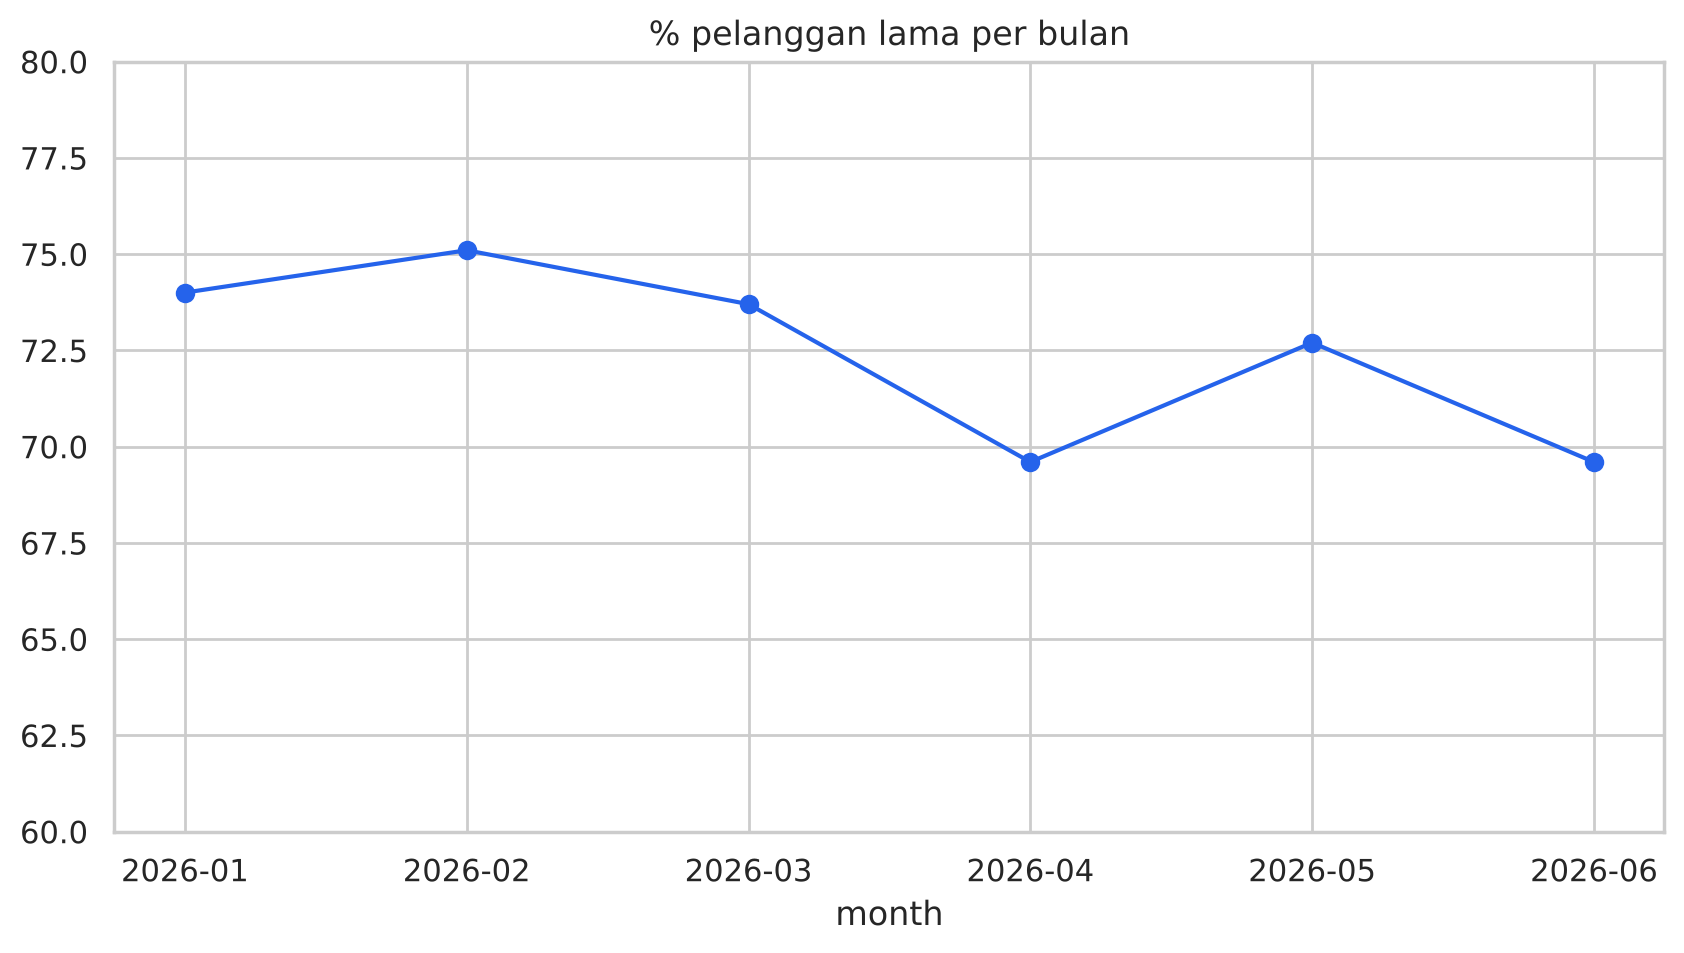

In [12]:
od = df[df.dropoff_area != "Unknown"].groupby(["pickup_area","dropoff_area"]).size().sort_values(ascending=False); print("Rute teratas:"); print(od.head(5))
print("\nTujuan Bandara+Stasiun: %", round(df.dropoff_area.isin(["Bandara Ahmad Yani","Stasiun Tawang"]).mean()*100, 1))
r = df.groupby("month").customer_type.apply(lambda s: (s == "Returning Customer").mean()*100).round(1); print("\n% pelanggan lama per bulan:"); print(r)
r.plot(marker="o", color="#2563EB"); plt.ylim(60, 80); plt.title("% pelanggan lama per bulan"); plt.show()

**Insight:** Rute terpadat hanya ±56 perjalanan dari 4.000, jadi tidak ada koridor dominan. Porsi pelanggan lama turun dari ±74–75% (Jan–Feb) menjadi ±69,6% (April dan Juni), perlu dipantau lewat program loyalitas.

## 10. Kesimpulan & Rekomendasi
| Temuan | Rekomendasi |
|---|---|
| Puncak jam 07–08 dan 17–19 | Tambah insentif driver dan ketersediaan armada di jam puncak |
| Dini hari sangat sepi | Kurangi armada aktif atau beri bonus kecil untuk menjaga ketersediaan |
| Tarif Mobil per km jauh lebih tinggi | Promosikan Mobil untuk perjalanan jauh atau berkelompok |
| Permintaan merata antar area | Fokuskan promo berdasarkan jam, bukan hanya area |
| Pelanggan lama ±73% | Pertahankan dengan program loyalitas; kejar pelanggan baru lewat referral |

**Keterbatasan:** data tidak memuat biaya, jumlah driver, atau tarif dinamis (surge), sehingga analisis fokus pada permintaan dan pendapatan kotor.